## 函数设定

In [1]:
import os,sys
import pandas as pd 
import matplotlib.pyplot as plt
import numpy as np
import natsort
import math
import seaborn as sns
plt.rcParams['font.sans-serif'] = ['SimHei']  # 用来正常显示中文标签
plt.rcParams['axes.unicode_minus'] = False  # 用来正常显示负号

In [3]:
# 导入单个数据数据集的函数
def get_spectrums_form_HORIBA(data_path,begin_label=0,end_label=2000):
    with open(data_path,'r') as f:
        data = f.read()
        # spec_count = data.count('\n')

        if data.endswith('\n'):
            spec_count = data.count('\n')  # 最后一行是空行
        else:
            spec_count = data.count('\n') + 1  # 最后一行不是空行
            
        data = np.fromstring(data, dtype=float, sep='\t')

        resolution = math.ceil(len(data)/(spec_count))
        
        if (len(data)-resolution+1) % (resolution) == 0:
            raman_shift = data[:(resolution-1)] # 第一行是raman shift
            spec_data = data[(resolution-1):] # 第二行开始是拉曼光谱
            spec_data = spec_data.reshape(-1,resolution)
            spec_data = spec_data[:,1:] #删掉第一列
            # print(f"spectrum resolution = {resolution-1}")

        elif (len(data)-resolution+2) % (resolution) == 0:
            raman_shift = data[:(resolution-2)] # 第一行是raman shift
            spec_data = data[(resolution-2):] # 第二行开始是拉曼光谱
            spec_data = spec_data.reshape(-1,resolution)
            spec_data = spec_data[:,2:] #删掉前两列
            # print(f"spectrum resolution = {resolution-2}")

        else:
            raman_shift = data[:(resolution)] # 第一行是raman shift
            spec_data = data[resolution:] # 第二行开始是拉曼光谱
            spec_data = spec_data.reshape(-1,resolution)
            # print(f"spectrum resolution = {resolution}")

    raman_shift = raman_shift[begin_label:end_label]
    spec_data = spec_data[:,begin_label:end_label]
    # print(f"Cutted resolution = {len(raman_shift)}")

    data = {"Raman Shift":raman_shift,"Intensity":spec_data}
    return data

# data_path = r"C:\Users\32916\Desktop\脑脊液病人拉曼光谱分类\有颅咽管瘤\data_56\CSF3-2-30min_1s_200spectra_s03_Cut67-973_20241113144229_Corrected_20241113160830.txt"
# data = get_spectrums_form_HORIBA(data_path,begin_label=0,end_label=907)
# plt.figure(figsize=(10,8),dpi=100)
# plt.plot(data["Raman Shift"],data["Intensity"][0])
# np.shape(data["Intensity"])

# 计算光谱的一阶导数，且保持数组长度不变
def get_first_derivative(data):
    first_derivative = np.zeros_like(data)
    first_derivative[1:-1] = (data[2:] - data[:-2]) / 2
    first_derivative[0] = (data[1] - data[0])
    first_derivative[-1] = (data[-1] - data[-2])
    return first_derivative

## 导入数据集

In [10]:
## 可调整参数
# 数据及标签文件路径
data_path = r'C:\Users\YY\Desktop\CSF-数据处理\ML-Classification-25-12-16\data\data\有颅咽管瘤\data_56'
label_path = r'C:\Users\YY\Desktop\CSF-数据处理\ML-Classification-25-12-16\data\data\data_id_label.xlsx'
# 数据预处理参数
begin_label = 0 # 光谱截取起始点
end_label = 2000 # 光谱截取终止点
group_spec_num = 1  # 每组光谱的数量，取1就代表不平均
cal_derivative = False # 是否计算光谱的一阶导数

In [12]:
# 原始数据的存储路径
files = os.listdir(data_path)
# 检索该路径下的所有文件名
name_list = []
for file in files:
    if 'txt' in file: # 收集所有txt文件
        name_list.append(file)
name_list = natsort.natsorted(name_list) # 对文件名进行自然排序
name_list

['CSF1-2-30min_1s_200spectra_s03_Cut67-973_20241113142010_Corrected_20241113160825.txt',
 'CSF2-2-30min_1s_200spectra_s03_Cut67-973_20241113143005_Corrected_20241113160827.txt',
 'CSF3-2-30min_1s_200spectra_s03_Cut67-973_20241113144229_Corrected_20241113160830.txt',
 'CSF4-2-30min_1s_200spectra_s03_Cut67-973_20241113145156_Corrected_20241113160832.txt',
 'CSF5-2-30min_1s_200spectra_s03_Cut67-973_20241113145708_Corrected_20241113160835.txt',
 'CSF6-2-30min_1s_200spectra_s03_Cut67-973_20241113150656_Corrected_20241113160837.txt',
 'CSF7-2-30min_1s_200spectra_s03_Cut67-973_20241107170147_Corrected_20241107174409.txt',
 'CSF8-2-30min_1s_200spectra_s03_Cut67-973_20241107173327_Corrected_20241107174812.txt',
 'CSF9-2-30min_1s_200spectra_s03_Cut67-973_20241111122410_Corrected_20241112134938.txt',
 'CSF10-2-30min_1s_200spectra_s03_Cut67-973_20241111122919_Corrected_20241112134941.txt',
 'CSF13-2-30min_1s_200spectra_s03_Cut67-973_20241111162908_Corrected_20241112134948.txt',
 'CSF14-2-30min_1s_

In [14]:
# 导入标签的表格
label = np.array(pd.read_excel(label_path)["label"])
id = np.array(pd.read_excel(label_path)["id"])

### 生成单张光谱数据集

In [77]:
# 生成大数据表格（单张光谱分析）
data_id = []
data_label = []
dataset = []
for i in range(len(name_list)):
    data = get_spectrums_form_HORIBA(os.path.join(data_path,name_list[i]),begin_label=begin_label,end_label=end_label)
    intensity = np.array(data["Intensity"])

    ## 数据预处理步骤

    # 取平均光谱，作为该id的代表性光谱
    intensity_group = np.reshape(intensity,(group_spec_num,int(len(intensity)/group_spec_num),intensity.shape[1]))
    intensity_mean = intensity_group.mean(axis=0)

    # 逐个计算intensity_mean光谱的一阶导数
    if cal_derivative:
        for j in range(intensity_mean.shape[0]):
            intensity_mean[j] = get_first_derivative(intensity_mean[j])

    raman_shift = np.array(data["Raman Shift"])
    dataset.append(intensity_mean)
    data_len = len(intensity_mean)
    # 重复插入第i个id，直到长度为data_len
    data_id.extend([id[i]]*data_len)
    # 重复插入第i个label，直到长度为data_len
    data_label.extend([label[i]]*data_len)

data_id = np.array(data_id)
data_label = np.array(data_label)
dataset = np.array(dataset)
# 按照第一个维度拼接在一起
dataset = np.concatenate(dataset,axis=0)

print("数据集形状为：",np.shape(dataset))
print("标签形状为：",np.shape(data_label))
print("id形状为：",np.shape(data_id))

数据集形状为： (11200, 907)
标签形状为： (11200,)
id形状为： (11200,)


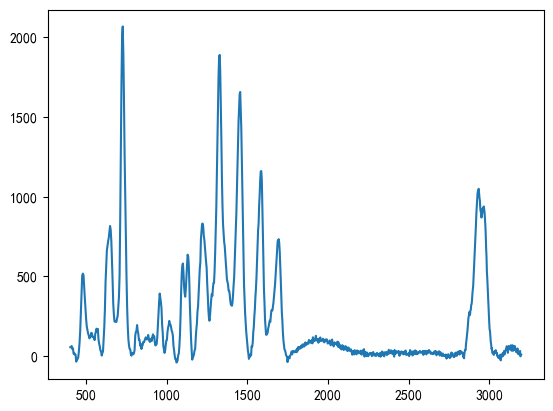

In [78]:
# 观察计算出来的光谱是否有问题
plt.plot(raman_shift,intensity_mean[0])

### 生成光谱集数据集

In [17]:
## 光谱集数据的构建
data_id = []
data_label = []
dataset = []
for i in range(len(name_list)):
    data = get_spectrums_form_HORIBA(os.path.join(data_path,name_list[i]),begin_label=begin_label,end_label=end_label)
    intensity = np.array(data["Intensity"])

    ## 数据预处理步骤

    # 取平均光谱，作为该id的代表性光谱
    intensity_group = np.reshape(intensity,(group_spec_num,int(len(intensity)/group_spec_num),intensity.shape[1]))
    intensity_mean = intensity_group.mean(axis=0)

    # 逐个计算intensity_mean光谱的一阶导数
    if cal_derivative:
        for j in range(intensity_mean.shape[0]):
            intensity_mean[j] = get_first_derivative(intensity_mean[j])

    raman_shift = np.array(data["Raman Shift"])
    dataset.append(intensity_mean)
    data_id.append(id[i])
    data_label.append(label[i])
    

dataset = np.array(dataset)
data_id = np.array(data_id)
data_label = np.array(data_label)

print("数据集形状为：",np.shape(dataset))
print("标签形状为：",np.shape(data_label))
print("id形状为：",np.shape(data_id))

数据集形状为： (56, 200, 907)
标签形状为： (56,)
id形状为： (56,)


<Axes: >

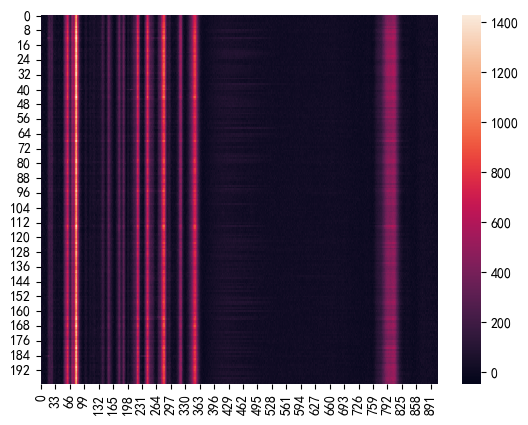

In [19]:
# 绘制光谱集图像
plt.figure()
sns.heatmap(dataset[0])

## 导入外部（未知光谱）数据集

In [24]:
unknown_data_path = r'C:\Users\YY\Desktop\CSF-数据处理\ML-Classification-25-12-16\data\data\有颅咽管瘤\data_unknown'
files = os.listdir(unknown_data_path)
# 检索该路径下的所有文件名
name_list = []
for file in files:
    if 'txt' in file: # 收集所有txt文件
        name_list.append(file)
name_list = natsort.natsorted(name_list) # 对文件名进行自然排序
name_list
unknown_dataset = []
for i in range(len(name_list)):
    data = get_spectrums_form_HORIBA(os.path.join(unknown_data_path,name_list[i]),begin_label=begin_label,end_label=end_label)
    intensity = np.array(data["Intensity"])
    intensity_group = np.reshape(intensity,(group_spec_num,int(len(intensity)/group_spec_num),intensity.shape[1]))

    intensity_mean = intensity_group.mean(axis=0)
    if cal_derivative:
        for j in range(intensity_mean.shape[0]):
            intensity_mean[j] = get_first_derivative(intensity_mean[j])
    raman_shift = np.array(data["Raman Shift"])
    unknown_dataset.append(intensity_mean)
unknown_dataset = np.array(unknown_dataset)
print("未知数据集形状为：",np.shape(unknown_dataset))

未知数据集形状为： (6, 200, 907)


## 数据集的划分

In [27]:
## 可调整参数
testing_id = [9, 36, 41, 48, 49, 50, 51, 52, 54]

In [29]:
training_id = [i for i in id if i not in testing_id]

training_data = dataset[np.isin(data_id,training_id)]
print("训练集形状为：",np.shape(training_data))
testing_data = dataset[np.isin(data_id,testing_id)]
print("测试集形状为：",np.shape(testing_data))

training_data_id = data_id[np.isin(data_id,training_id)]
testing_data_id = data_id[np.isin(data_id,testing_id)]
training_data_label = data_label[np.isin(data_id,training_id)]
testing_data_label = data_label[np.isin(data_id,testing_id)]
print("训练集id形状为：",np.shape(training_data_id))
print("测试集id形状为：",np.shape(testing_data_id))
print("训练集标签形状为：",np.shape(training_data_label))
print("测试集标签形状为：",np.shape(testing_data_label))

训练集形状为： (47, 200, 907)
测试集形状为： (9, 200, 907)
训练集id形状为： (47,)
测试集id形状为： (9,)
训练集标签形状为： (47,)
测试集标签形状为： (9,)


In [31]:
# 合并内部测试集和外部测试集（对于光谱集数据）
testing_data = np.concatenate((testing_data,unknown_dataset),axis=0)
testing_data_label = np.concatenate((testing_data_label,np.array([1,0,0,0,0,0])),axis=0)
print("合并后的测试集形状为：",np.shape(testing_data))
print("合并后的测试集标签形状为：",np.shape(testing_data_label))

合并后的测试集形状为： (15, 200, 907)
合并后的测试集标签形状为： (15,)


In [33]:
# 合并内部测试集和外部测试集（对于单光谱数据）
unknown_dataset_reshape = np.reshape(unknown_dataset,(-1,unknown_dataset.shape[2]))
testing_data = np.concatenate((testing_data,unknown_dataset_reshape),axis=0)

unknown_datalabel = np.repeat(np.array([1,0,0,0,0,0]),unknown_dataset.shape[1],axis=0)
testing_data_label = np.concatenate((testing_data_label,unknown_datalabel),axis=0)
print("合并后的测试集形状为：",np.shape(testing_data))
print("合并后的测试集标签形状为：",np.shape(testing_data_label))

ValueError: all the input arrays must have same number of dimensions, but the array at index 0 has 3 dimension(s) and the array at index 1 has 2 dimension(s)

## 数据降维

In [35]:
# 可调整参数
n_components = 30
alpha = 0.5 # 调整散点图透明度

### 光谱集数据集降维先跑这个

In [37]:
# 把training_data和testing_data都拉直为一维
training_data = training_data.reshape(training_data.shape[0],-1)
testing_data = testing_data.reshape(testing_data.shape[0],-1)
print(np.shape(training_data))

(47, 181400)


### 光谱数据集降维

不同的数据降维方式分为不同的单元格，想要用哪种就跑哪个单元格，其他的不跑，不降维就跑第一个

In [28]:
# 不降维
training_data_reduced = training_data
testing_data_reduced = testing_data

In [39]:
# PCA降维, 可选择主成分个数范围为[0,max(n_sample,n_feature)]
from sklearn.decomposition import PCA
pca = PCA(n_components=n_components,random_state=0)
# pca = PCA(n_components=0.9)
data_to_reduce = np.concatenate((training_data,testing_data),axis=0)

data_reduced = pca.fit_transform(data_to_reduce)
training_data_reduced = data_reduced[0:len(training_data),:]
testing_data_reduced = data_reduced[len(training_data):,:]

print("PCA降维后的训练集形状为：",np.shape(training_data_reduced))
print("PCA降维后的测试集形状为：",np.shape(testing_data_reduced))
## 可视化结果
# # 绘制主成分贡献率图像
# plt.figure()
# plt.plot(pca.explained_variance_ratio_ * 100)
# # 绘制主成分累计贡献率图像
# plt.figure()
# plt.plot(np.cumsum(pca.explained_variance_ratio_ * 100))
# # 画y=90和y=95的线
# plt.axhline(y=90, color='r', linestyle='--')
# plt.axhline(y=95, color='g', linestyle='--')

PCA降维后的训练集形状为： (47, 30)
PCA降维后的测试集形状为： (15, 30)


In [14]:
# tSNE降维, tSNE似乎不能先降维后保存模型，然后对于测试集降维，所以这里直接对训练集和测试集分别降维；tSNE只能降维成2-3维
from sklearn.manifold import TSNE
tsne = TSNE(n_components=3, random_state=0)
training_data_reduced = tsne.fit_transform(training_data)
print("t-SNE降维后的训练集形状为：",np.shape(training_data_reduced))
testing_data_reduced = tsne.fit_transform(testing_data)
print("t-SNE降维后的测试集形状为：",np.shape(testing_data_reduced))

t-SNE降维后的训练集形状为： (7600, 3)
t-SNE降维后的测试集形状为： (3600, 3)


In [15]:
# umap降维
from umap import UMAP
umap = UMAP(n_components=100, random_state=0)
training_data_reduced = umap.fit_transform(training_data)
print("UMAP降维后的训练集形状为：",np.shape(training_data_reduced))
testing_data_reduced = umap.transform(testing_data)
print("UMAP降维后的测试集形状为：",np.shape(testing_data_reduced))

c:\Users\32916\.conda\envs\torch_py39\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\32916\.conda\envs\torch_py39\lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


UMAP降维后的训练集形状为： (7600, 100)
UMAP降维后的测试集形状为： (3600, 100)


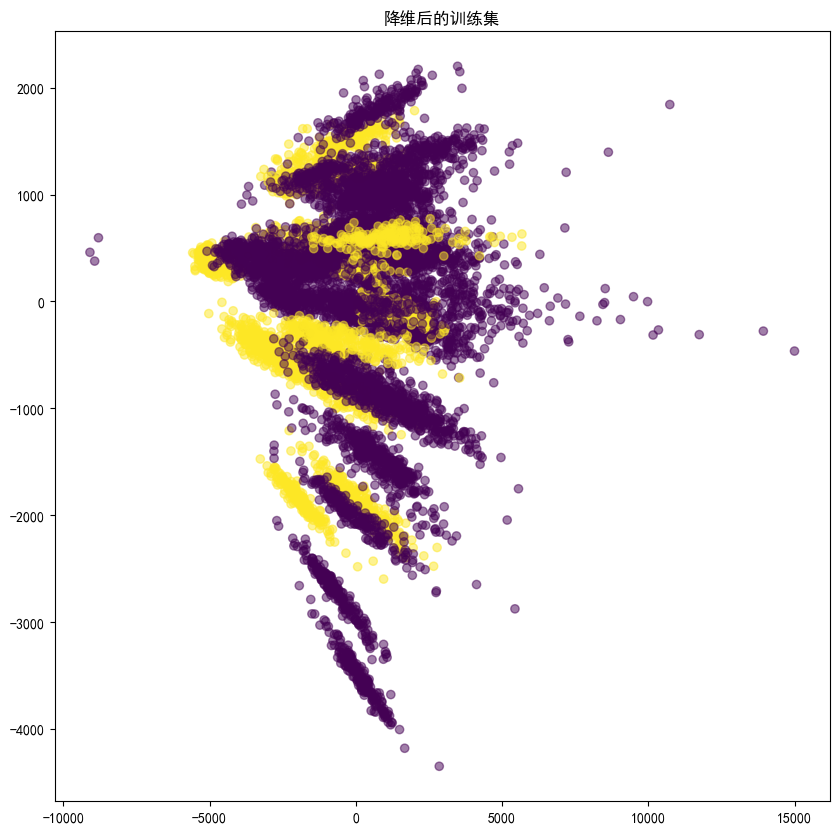

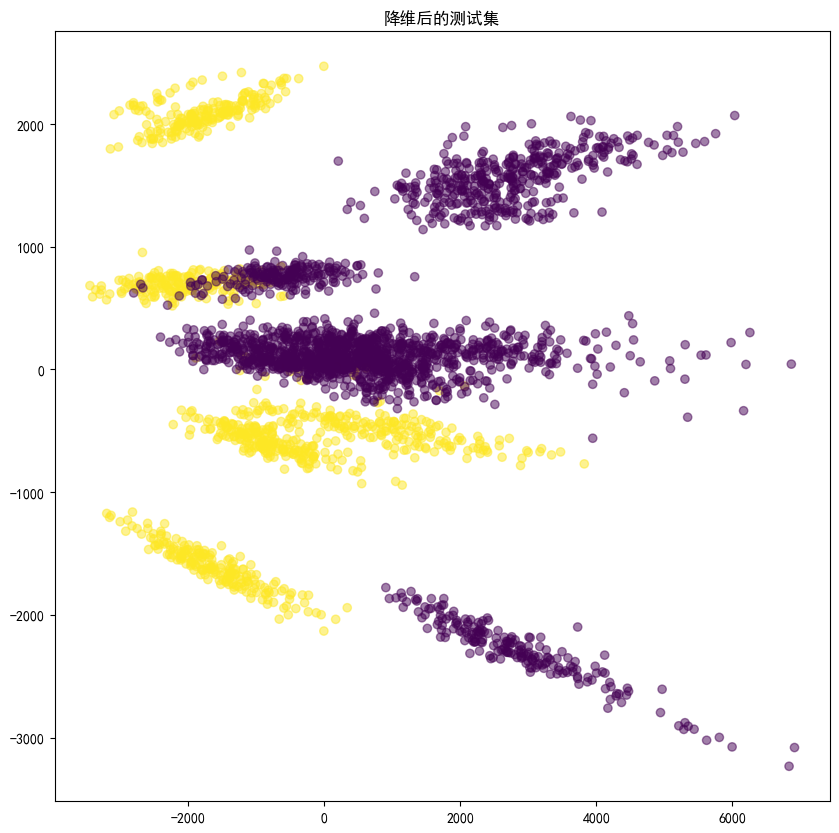

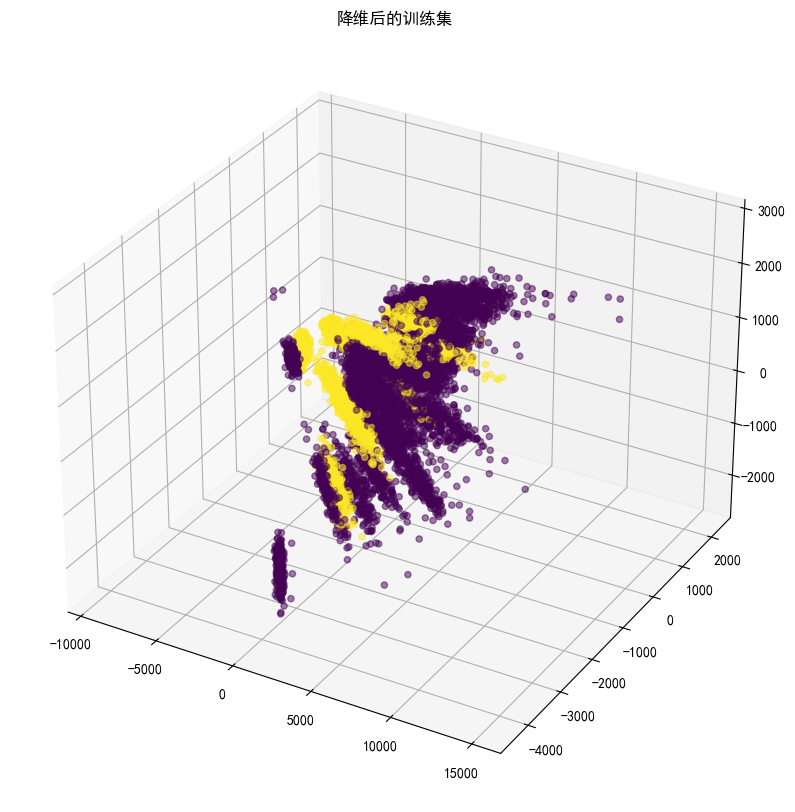

In [88]:
# 绘制降维后的数据
plt.figure(figsize=(10, 10))
plt.scatter(training_data_reduced[:, 0], training_data_reduced[:, 1], c=training_data_label, cmap='viridis', alpha=alpha)
plt.title('降维后的训练集')
plt.show()
plt.figure(figsize=(10, 10))
plt.scatter(testing_data_reduced[:, 0], testing_data_reduced[:, 1], c=testing_data_label, cmap='viridis', alpha=alpha)
plt.title('降维后的测试集')
plt.show()

## 绘制前三个主成分的三维图
from mpl_toolkits.mplot3d import Axes3D
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(training_data_reduced[:, 0], training_data_reduced[:, 1], training_data_reduced[:, 2], c=training_data_label, cmap='viridis', alpha=alpha)
ax.set_title('降维后的训练集')
plt.show()

## 训练分类模型

不同的分类模型写在不同单元格中，想要用哪种就跑哪个单元格，其他的不跑

In [41]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix


def draw_confusion_matrix(label_true, label_pred, label_name, title="Confusion Matrix", pdf_save_path=None, dpi=100):
    """

    @param label_true: 真实标签，比如[0,1,2,7,4,5,...]
    @param label_pred: 预测标签，比如[0,5,4,2,1,4,...]
    @param label_name: 标签名字，比如['cat','dog','flower',...]
    @param title: 图标题
    @param pdf_save_path: 是否保存，是则为保存路径pdf_save_path=xxx.png | xxx.pdf | ...等其他plt.savefig支持的保存格式
    @param dpi: 保存到文件的分辨率，论文一般要求至少300dpi
    @return:

    example：
            draw_confusion_matrix(label_true=y_gt,
                          label_pred=y_pred,
                          label_name=["Angry", "Disgust", "Fear", "Happy", "Sad", "Surprise", "Neutral"],
                          title="Confusion Matrix on Fer2013",
                          pdf_save_path="Confusion_Matrix_on_Fer2013.png",
                          dpi=300)

    """
    # 计算混淆矩阵
    cm = confusion_matrix(label_true, label_pred)
    # 归一化混淆矩阵
    cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    plt.imshow(cm, cmap='Blues')
    # plt.title(title)
    plt.xlabel("Predict label", fontsize=20)
    plt.ylabel("Truth label", fontsize=20)
    plt.yticks(range(label_name.__len__()), label_name, fontsize=17)
    plt.xticks(range(label_name.__len__()), label_name, fontsize=17)

    plt.tight_layout()

    # plt.colorbar()

    for i in range(label_name.__len__()):
        for j in range(label_name.__len__()):
            color = (1, 1, 1) if i == j else (0, 0, 0)  # 对角线字体白色，其他黑色
            # 计算百分比
            percent = format('%.1f%%' % (cm_normalized[j, i] * 100))
            # 显示原始值和百分比
            value = f"{cm[j, i]} \n ({percent})"
            plt.text(i, j, value, verticalalignment='center', horizontalalignment='center', color=color, fontsize=20)

    # plt.show()
    if not pdf_save_path is None:
        plt.savefig(pdf_save_path, bbox_inches='tight', dpi=dpi)

In [90]:
## SVM分类
from sklearn.svm import SVC
model = SVC(kernel='rbf', C=1, gamma='auto', probability=True)
model.fit(training_data_reduced, training_data_label)

y_pred = model.predict(testing_data_reduced)
print(y_pred)
print("测试集准确率为：", accuracy_score(testing_data_label, y_pred))

y_scores = model.predict_proba(testing_data_reduced)[:, 1]
print(y_scores)

[0 0 0 ... 0 0 0]
测试集准确率为： 0.6666666666666666
[0.29773582 0.29773582 0.29773582 ... 0.29773582 0.29773582 0.29773582]


In [91]:
## KNN分类
from sklearn.neighbors import KNeighborsClassifier
model = KNeighborsClassifier(n_neighbors=5)
model.fit(training_data_reduced, training_data_label)

y_pred = model.predict(testing_data_reduced)
print(y_pred)
print("测试集准确率为：", accuracy_score(testing_data_label, y_pred))

# 对于KNN来说
y_scores = model.predict_proba(testing_data_reduced)[:, 1]
print(y_scores)

[0 0 0 ... 0 0 0]
测试集准确率为： 0.7196666666666667
[0. 0. 0. ... 0. 0. 0.]


In [43]:
## 决策树分类
from sklearn.tree import DecisionTreeClassifier
model = DecisionTreeClassifier(random_state=42)
model.fit(training_data_reduced, training_data_label)

y_pred = model.predict(testing_data_reduced)
print(y_pred)
print("测试集准确率为：", accuracy_score(testing_data_label, y_pred))

# 对于决策树来说
y_scores = model.predict_proba(testing_data_reduced)[:, 1]
print(y_scores)

[1 0 1 0 0 0 0 0 0 1 0 0 0 0 0]
测试集准确率为： 0.8666666666666667
[1. 0. 1. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]


In [93]:
## 随机森林分类
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=2)
model.fit(training_data_reduced, training_data_label)

y_pred = model.predict(testing_data_reduced)
print(y_pred)
print("测试集准确率为：", accuracy_score(testing_data_label, y_pred))

# 对于随机森林来说
y_scores = model.predict_proba(testing_data_reduced)[:, 1]
print(y_scores)

[0 0 1 ... 0 0 0]
测试集准确率为： 0.72
[0.46135497 0.34135361 0.50828435 ... 0.16260831 0.24611881 0.29506578]


In [94]:
## LDA分类，注意该分类器
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
model = LinearDiscriminantAnalysis()
model.fit(training_data_reduced, training_data_label)

y_pred = model.predict(testing_data_reduced)
print(y_pred)
print("测试集准确率为：", accuracy_score(testing_data_label, y_pred))

# 对于LDA来说
y_scores = model.predict_proba(testing_data_reduced)[:, 1]
print(y_scores)

[1 1 1 ... 0 0 0]
测试集准确率为： 0.81
[9.90708164e-01 9.96391959e-01 9.98122906e-01 ... 7.44560181e-06
 2.03454247e-06 2.54325036e-06]


## 模型的评估

绘制ROC曲线和混淆矩阵

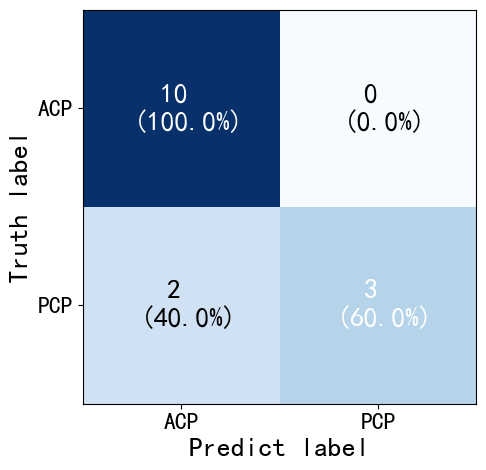

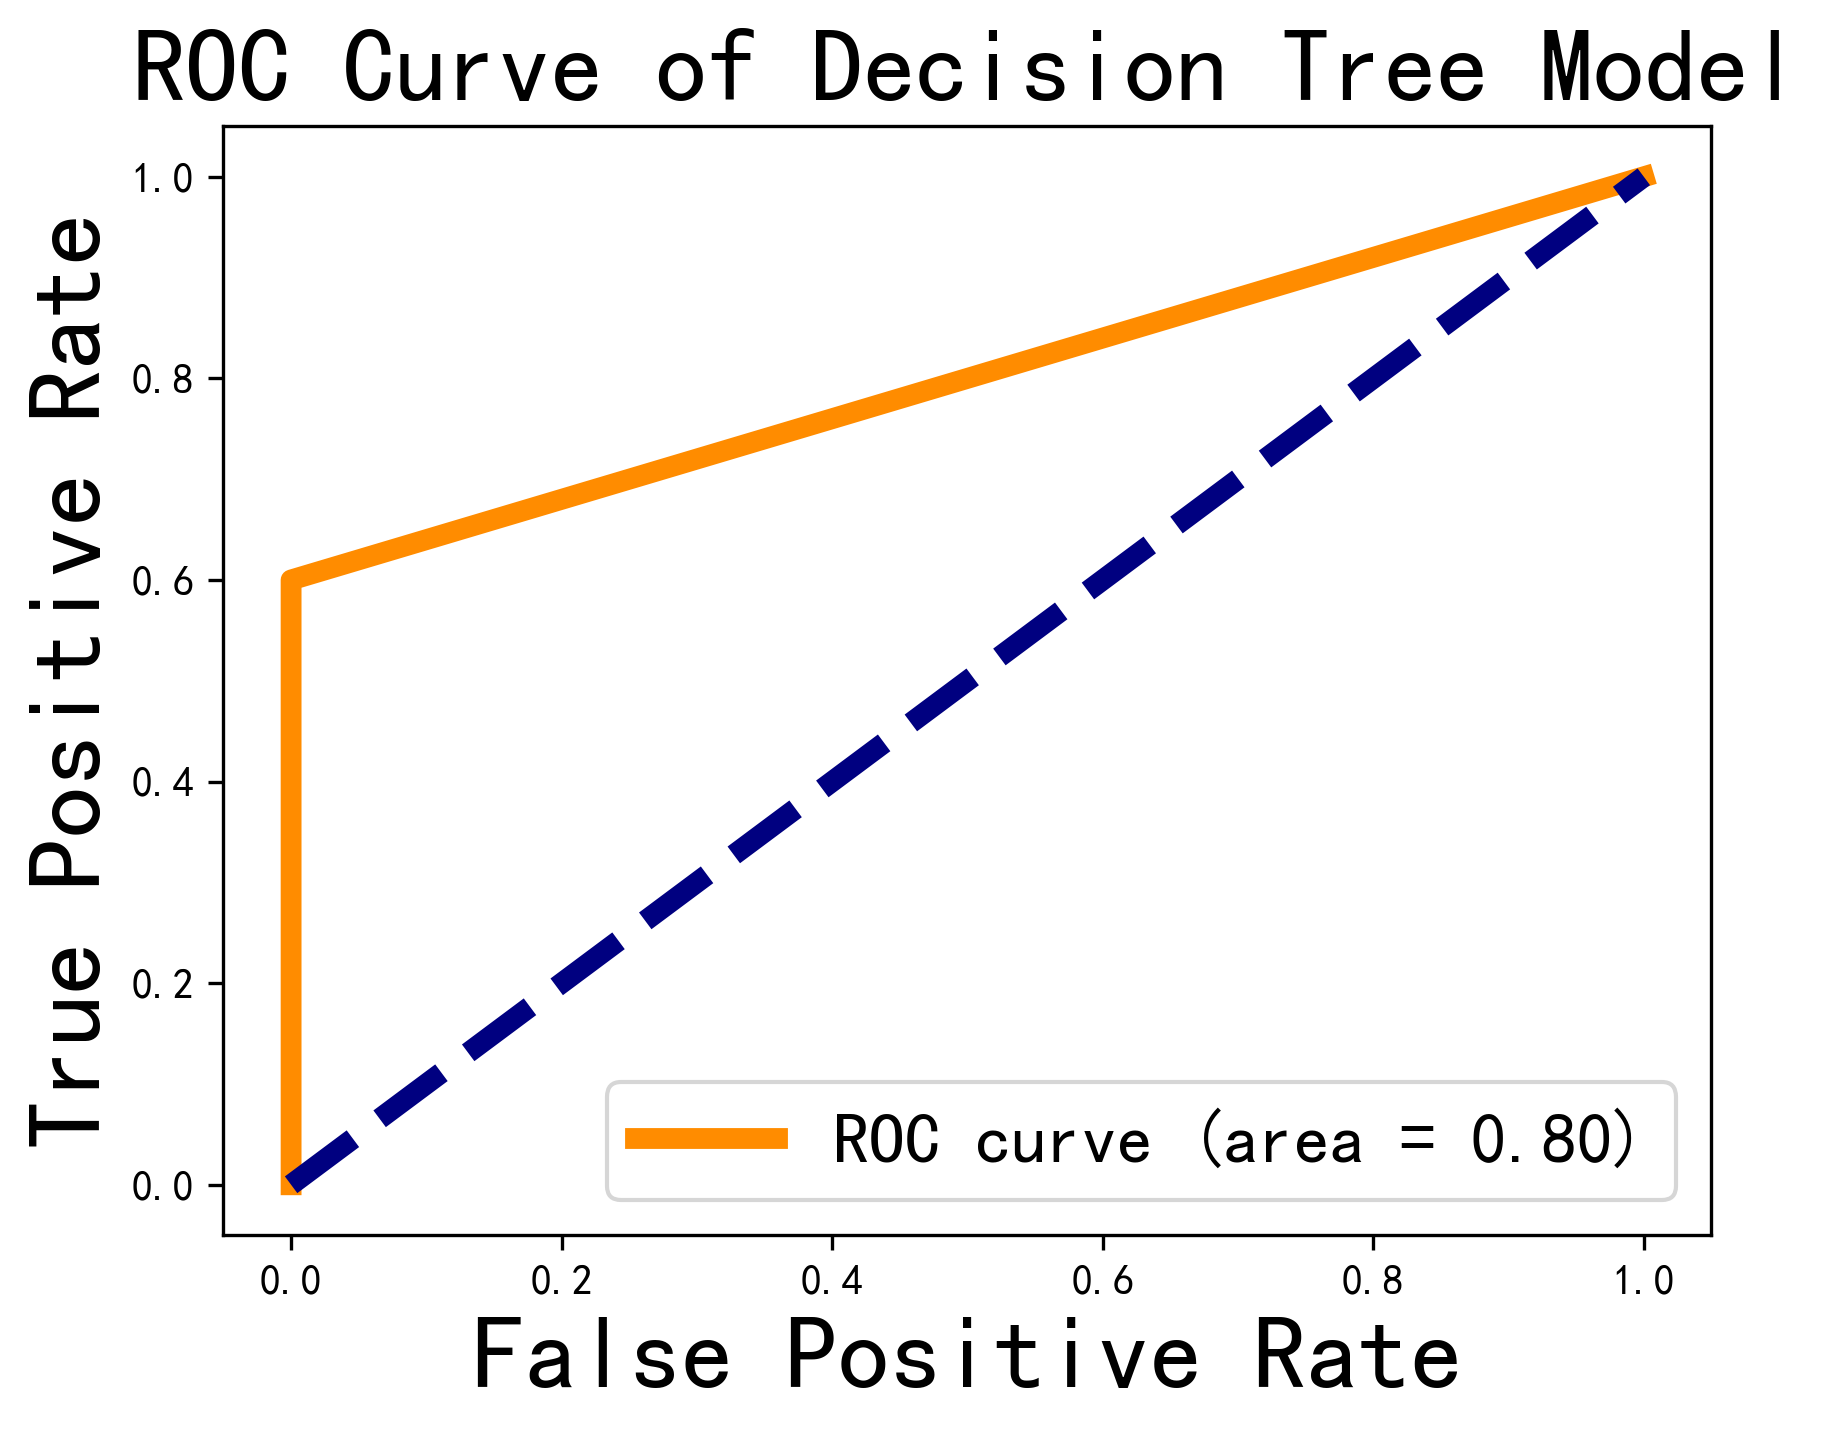

In [45]:
## 模型评估
# 绘制混淆矩阵热图
draw_confusion_matrix(label_true=testing_data_label,label_pred=y_pred,label_name=['ACP','PCP'],title="Confusion Matrix of CNN Model",pdf_save_path="Confusion_Matrix_of_machine_learning_Matrix.png",dpi=300)

# 绘制模型ROC曲线
from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(testing_data_label, y_scores)
roc_auc = auc(fpr, tpr)
plt.figure(dpi=300)
lw = 5
plt.plot(fpr, tpr, color='darkorange',
         lw=lw, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=lw, linestyle='--')
plt.xlim([-0.05, 1.05])
plt.ylim([-0.05, 1.05])
plt.xlabel('False Positive Rate', fontsize=25)
plt.ylabel('True Positive Rate', fontsize=25)
plt.title('ROC Curve of Decision Tree Model', fontsize=25)
plt.legend(loc="lower right", fontsize=17)
plt.show()
plt.close()

In [147]:
from sklearn.neighbors import KNeighborsClassifier
model = KNeighborsClassifier(n_neighbors=5)
model.fit(training_data_reduced, training_data_label)
y_pred = model.predict(testing_data_reduced)
print(y_pred)

[1 0 1 0 0 0 0 0 0 1 0 1 0 0 0]


样本9的分类结果为：
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       0.0
           1       0.00      0.00      0.00     200.0

    accuracy                           0.00     200.0
   macro avg       0.00      0.00      0.00     200.0
weighted avg       0.00      0.00      0.00     200.0

样本36的分类结果为：
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       0.0
           1       0.00      0.00      0.00     200.0

    accuracy                           0.00     200.0
   macro avg       0.00      0.00      0.00     200.0
weighted avg       0.00      0.00      0.00     200.0

样本41的分类结果为：
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       0.0
           1       0.00      0.00      0.00     200.0

    accuracy                           0.00     200.0
   macro avg       0.00      0.00      0.00     200.0
weighted avg       0.00      0.00      

c:\Users\32916\.conda\envs\torch_py39\lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\32916\.conda\envs\torch_py39\lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\32916\.conda\envs\torch_py39\lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\

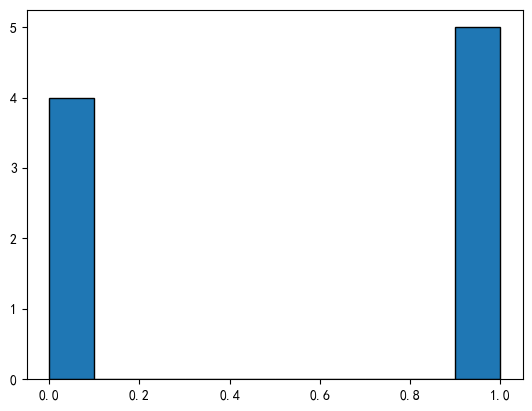

In [34]:
## 对于单光谱数据集，统计每个样本的分类结果
y_pred = model.predict(testing_data_reduced)
y_pred = y_pred.reshape(len(testing_id), int(len(y_pred)/len(testing_id)))
testing_data_label_ = testing_data_label.reshape(len(testing_id), int(len(testing_data_label)/len(testing_id)))

# 每个样本单独分析
for i in range(len(testing_id)):
    print("样本{}的分类结果为：".format(testing_id[i]))
    print(classification_report(testing_data_label_[i], y_pred[i]))

# 所有样本准确率的统计
accuracy = []
for i in range(len(testing_id)):
    accuracy.append(accuracy_score(testing_data_label_[i], y_pred[i]))
# 绘制直方图
plt.hist(accuracy, bins=10, edgecolor='black')
# 计算准确率高于50%和低于50%的样本数量
accuracy_50 = [i for i in accuracy if i >= 0.5]
accuracy_50 = len(accuracy_50)
accuracy_50_ = [i for i in accuracy if i < 0.5]
accuracy_50_ = len(accuracy_50_)
print("准确率高于50%的样本数量为：", accuracy_50)
print("准确率低于50%的样本数量为：", accuracy_50_)

### 光谱集使用CNN分类

In [13]:
import numpy as np
from torchvision import models, transforms, utils, datasets
import cv2
from PIL import Image
from torch.nn import functional as F
import torch
import torch.nn as nn
from torch import Tensor
from torch.utils.data import Dataset,DataLoader
import torch.utils.data as Data
import matplotlib.pyplot as plt
import pandas as pd
import warnings#而这两句则是为了将程序运行时的警告显示去除用的
warnings.filterwarnings("ignore")
import os
import torchvision
import sys
from sklearn.decomposition import PCA
import natsort

#### 导入数据

In [4]:
## 可调整参数
# 数据及标签文件路径
data_path = r'D:\XHQ_study_data\ING\脑脊液病人拉曼光谱分类\data\有颅咽管瘤\data_56'
label_path = r'D:\XHQ_study_data\ING\脑脊液病人拉曼光谱分类\data\data_id_label.xlsx'
# 数据预处理参数
begin_label = 0 # 光谱截取起始点
end_label = 2000 # 光谱截取终止点
group_spec_num = 1  # 每组光谱的数量，取1就代表不平均
cal_derivative = False # 是否计算光谱的一阶导数

In [5]:
# 原始数据的存储路径
files = os.listdir(data_path)
# 检索该路径下的所有文件名
name_list = []
for file in files:
    if 'txt' in file: # 收集所有txt文件
        name_list.append(file)
name_list = natsort.natsorted(name_list) # 对文件名进行自然排序
name_list

# 导入标签的表格
label = np.array(pd.read_excel(label_path)["label"])
id = np.array(pd.read_excel(label_path)["id"])

## 光谱集数据的构建
data_id = []
data_label = []
dataset = []
for i in range(len(name_list)):
    data = get_spectrums_form_HORIBA(os.path.join(data_path,name_list[i]),begin_label=begin_label,end_label=end_label)
    intensity = np.array(data["Intensity"])

    ## 数据预处理步骤

    # 取平均光谱，作为该id的代表性光谱
    intensity_group = np.reshape(intensity,(group_spec_num,int(len(intensity)/group_spec_num),intensity.shape[1]))
    intensity_mean = intensity_group.mean(axis=0)

    # 逐个计算intensity_mean光谱的一阶导数
    if cal_derivative:
        for j in range(intensity_mean.shape[0]):
            intensity_mean[j] = get_first_derivative(intensity_mean[j])

    raman_shift = np.array(data["Raman Shift"])
    dataset.append(intensity_mean)
    data_id.append(id[i])
    data_label.append(label[i])
    

dataset = np.array(dataset)
data_id = np.array(data_id)
data_label = np.array(data_label)

print("数据集形状为：",np.shape(dataset))
print("标签形状为：",np.shape(data_label))
print("id形状为：",np.shape(data_id))


数据集形状为： (56, 200, 907)
标签形状为： (56,)
id形状为： (56,)


In [6]:
unknown_data_path = r'D:\XHQ_study_data\ING\脑脊液病人拉曼光谱分类\data\有颅咽管瘤\data_unknown'
files = os.listdir(unknown_data_path)
# 检索该路径下的所有文件名
name_list = []
for file in files:
    if 'txt' in file: # 收集所有txt文件
        name_list.append(file)
name_list = natsort.natsorted(name_list) # 对文件名进行自然排序
name_list
unknown_dataset = []
for i in range(len(name_list)):
    data = get_spectrums_form_HORIBA(os.path.join(unknown_data_path,name_list[i]),begin_label=begin_label,end_label=end_label)
    intensity = np.array(data["Intensity"])
    intensity_group = np.reshape(intensity,(group_spec_num,int(len(intensity)/group_spec_num),intensity.shape[1]))

    intensity_mean = intensity_group.mean(axis=0)
    if cal_derivative:
        for j in range(intensity_mean.shape[0]):
            intensity_mean[j] = get_first_derivative(intensity_mean[j])
    raman_shift = np.array(data["Raman Shift"])
    unknown_dataset.append(intensity_mean)
unknown_dataset = np.array(unknown_dataset)
print("未知数据集形状为：",np.shape(unknown_dataset))

未知数据集形状为： (6, 200, 907)


In [7]:
## 可调整参数
testing_id = [9, 36, 41, 48, 49, 50, 51, 52, 54, 55, 56, 57, 60, 62, 63, 65, 69, 70]

In [8]:
# 数据集划分
training_id = [i for i in id if i not in testing_id]

training_data = dataset[np.isin(data_id,training_id)]
print("训练集形状为：",np.shape(training_data))
testing_data = dataset[np.isin(data_id,testing_id)]
print("测试集形状为：",np.shape(testing_data))

training_data_id = data_id[np.isin(data_id,training_id)]
testing_data_id = data_id[np.isin(data_id,testing_id)]
training_data_label = data_label[np.isin(data_id,training_id)]
testing_data_label = data_label[np.isin(data_id,testing_id)]
print("训练集id形状为：",np.shape(training_data_id))
print("测试集id形状为：",np.shape(testing_data_id))
print("训练集标签形状为：",np.shape(training_data_label))
print("测试集标签形状为：",np.shape(testing_data_label))

# smote = SMOTE(random_state=0)
# x_train_smote, y_train_smote = smote.fit_resample(training_data, training_data_label)

训练集形状为： (38, 200, 907)
测试集形状为： (18, 200, 907)
训练集id形状为： (38,)
测试集id形状为： (18,)
训练集标签形状为： (38,)
测试集标签形状为： (18,)


#### 光谱集降维

In [9]:
n_components = 200
# PCA降维, 可选择主成分个数范围为[0,max(n_sample,n_feature)]
pca = PCA(n_components=n_components,random_state=0)
# training_data_reduced = []
# for i in range(len(training_data)):
#     training_data_reduced_tmp = pca.fit_transform(training_data[i])
#     training_data_reduced.append(training_data_reduced_tmp)

data_to_reduce = np.concatenate((training_data,testing_data),axis=0)

data_reduced = pca.fit_transform(data_to_reduce.reshape(-1,data_to_reduce.shape[2]))
data_reduced = data_reduced.reshape(-1,training_data.shape[1],n_components)
training_data_reduced = data_reduced[0:38,:,:]
testing_data_reduced = data_reduced[38:,:,:]

print("PCA降维后的训练集形状为：",np.shape(training_data_reduced))
print("PCA降维后的测试集形状为：",np.shape(testing_data_reduced))


PCA降维后的训练集形状为： (38, 200, 200)
PCA降维后的测试集形状为： (18, 200, 200)


<Axes: >

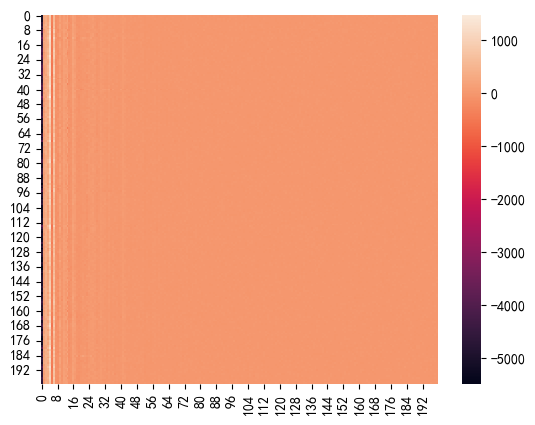

In [10]:
# 绘制降维后的热图
sns.heatmap(training_data_reduced[0])

In [14]:
data_unknown_reduced = pca.transform(unknown_dataset.reshape(-1,unknown_dataset.shape[2]))
data_unknown_reduced = data_unknown_reduced.reshape(-1,unknown_dataset.shape[1],n_components)
print("PCA降维后的未知数据集形状为：",np.shape(data_unknown_reduced))

PCA降维后的未知数据集形状为： (6, 200, 200)


In [15]:
x_train = np.expand_dims(training_data_reduced, axis=1)
x_test = np.expand_dims(testing_data_reduced, axis=1)[0:9,:,:,:]
x_valid = np.expand_dims(testing_data_reduced, axis=1)[9:,:,:,:]
y_train = training_data_label
y_test = testing_data_label[0:9]
y_valid = testing_data_label[9:]
print(x_train.shape, x_test.shape, x_valid.shape, y_train.shape, y_test.shape, y_valid.shape)

(38, 1, 200, 200) (9, 1, 200, 200) (9, 1, 200, 200) (38,) (9,) (9,)


In [16]:
x_unknown = np.expand_dims(data_unknown_reduced, axis=1)
print(x_unknown.shape)

(6, 1, 200, 200)


In [13]:
# 统计y_train中0和1分别有多少
print("训练集标签中0和1的数量分别为：",np.sum(y_train==0),np.sum(y_train==1))

训练集标签中0和1的数量分别为： 26 12


#### 解决数据均衡性问题
以Imbalancd sklearn库收录的算法来看，过采样共有11种方法，欠采样共有8种方法，组合采样有2种方法  
欠采样算法：RandomUnderSampler，ClusterCentroids，CondensedNearestNeighbour，RepeatedEditedNearestNeighbours，AllKNN；  
过采样方法：SMOTE，RandomOverSampler，ADASYN；  
组合采样方法：SMOTETomek/SMOTEENN  
https://cloud.tencent.com/developer/article/2384386  
  
调整交叉熵权重解决样本不均衡问题：  
https://blog.csdn.net/notHeadache/article/details/82183503  
https://www.svds.com/learning-imbalanced-classes/

In [88]:
# from imblearn.over_sampling import SMOTE
# from imblearn.under_sampling import RandomUnderSampler
# from imblearn.combine import SMOTETomek
# from imblearn.combine import SMOTEENN   
# # 采样
# # # 采样方法：SMOTE
# # smote = SMOTE(random_state=0)
# # x_train_smote, y_train_smote = smote.fit_resample(x_train, y_train)
# # 采样方法：RandomUnderSampler
# rus = RandomUnderSampler(random_state=0)
# x_train_rus, y_train_rus = rus.fit_resample(x_train, y_train)
# # # 采样方法：SMOTETomek
# # smotetomek = SMOTETomek(random_state=0)
# # x_train_smotetomek, y_train_smotetomek = smotetomek.fit_resample(x_train, y_train)
# # # 采样方法：SMOTEENN
# # smoteenn = SMOTEENN(random_state=0)
# # x_train_smoteenn, y_train_smoteenn = smoteenn.fit_resample(x_train, y_train)


#### 构建Dataloader及网络

In [17]:
class MyDataset(Data.Dataset):
    def __init__(self, data, targets, transform=None):
        self.data = data
        self.targets = targets
        self.transform = transform
    
    def __len__(self):
        return len(self.data)
    
    def __getitem__(self, index):
        x = self.data[index]
        y = self.targets[index]
        return x, y

data_transform = transforms.Compose([
 transforms.ToTensor()
])

batch_size=16

datasets = {
        "train": MyDataset(x_train,y_train,transform=data_transform),
        "valid": MyDataset(x_valid,y_valid,transform=data_transform),
        "test": MyDataset(x_test,y_test,transform=data_transform)
}

dataset_loader = {
    "train": torch.utils.data.DataLoader(datasets["train"], batch_size=batch_size, shuffle=True,pin_memory=False),
    "valid": torch.utils.data.DataLoader(datasets["valid"], batch_size=batch_size, shuffle=True,pin_memory=False),
    "test": torch.utils.data.DataLoader(datasets["test"], batch_size=batch_size, shuffle=True,pin_memory=False),
}

In [18]:
dataset_sizes = {
    x: len(datasets[x]) for x in datasets.keys()
}

print(dataset_sizes)
#for i, data in enumerate(zip(dataset_loader["train0"],dataset_loader["train1"])):
#    print(data)
#    break

for img, label in dataset_loader["train"]:
    print("tepoch的形状{}".format(img.shape))  
    print(label)
    break

{'train': 38, 'valid': 9, 'test': 9}
tepoch的形状torch.Size([16, 1, 200, 200])
tensor([0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0])


In [19]:
# 设备
device = 'cuda' if torch.cuda.is_available() else 'cpu'
cuda=1 if torch.cuda.is_available() else 0
device

'cuda'

In [15]:
class Net(nn.Module):
    def __init__(self) -> None:
        super(Net, self).__init__()
        
        self.conv1 = torch.nn.Sequential(
            torch.nn.Conv2d(1, 8, 3),
            torch.nn.ReLU())
        self.conv2 = torch.nn.Sequential(
            torch.nn.Conv2d(8, 16, 3),
            torch.nn.ReLU())
        self.conv3 = torch.nn.Sequential(
            torch.nn.Conv2d(16, 32, 3),
            torch.nn.ReLU())
        self.conv4 = torch.nn.Sequential(
            torch.nn.Conv2d(32, 64, 3),
            torch.nn.ReLU())
        self.maxpool = nn.MaxPool2d(3)
        self.fc = nn.Linear(64, 1)
        self.sig = nn.Sigmoid()
        
    def forward(self, x: Tensor) -> Tensor:
        out = self.conv1(x)
        out = self.maxpool(out)
        out = self.conv2(out)
        out = self.maxpool(out)
        out = self.conv3(out)
        out = self.maxpool(out)
        out = self.conv4(out)
        out = self.maxpool(out)
        # flatten
        out = torch.flatten(out,start_dim=1)
        # print(out.size())
        out = self.fc(out)
        out = self.sig(out)

        return out

In [16]:
import torch.optim as optim
from collections import defaultdict
from tqdm import tqdm

# 加权重
weights = torch.tensor([12/26],device=device)
criterion = nn.BCELoss(weight=weights)
# 未加权重
# criterion = nn.CrossEntropyLoss()

def calc_loss(pred, gt, metrics):
    batch = gt.size(0)
    # print(pred.squeeze(-1).size(),gt.size())
    loss = criterion(pred.squeeze(-1), gt)
    metrics['loss'] += loss.data.detach().cpu().numpy() * batch
    return loss
    print(pred.size,pred.squeeze().size,metrics['loss'])

def print_metrics(metrics, epoch_samples, phase):    
    outputs = []
    for k in metrics.keys():
        outputs.append("{}: {:5f}".format(k, metrics[k] / epoch_samples))
    print("{}: {}".format(phase, ", ".join(outputs)))    

def train_model(model, optimizer, scheduler, device, num_epochs=25):
    best_model_wts = copy.deepcopy(model.state_dict())
    best_loss = 1e10

    for epoch in range(num_epochs):
    #for epoch in range(1):
        print('Epoch {}/{}'.format(epoch, num_epochs - 1))
        print('-' * 10)
        
        since = time.time()

        # Each epoch has a training and validation phase
        for phase in ['train','valid']:
            right=0
            if phase == 'train':
                scheduler.step()
                for param_group in optimizer.param_groups:
                    print("LR", param_group['lr'])
                    
                model.train()  # Set model to training mode
            else:
                model.eval()   # Set model to evaluate mode
            metrics = defaultdict(float)
            epoch_samples = 0
            with tqdm(dataset_loader[phase], unit="batch") as tepoch:
                for inputs, labels in tepoch:
                    labels = labels.float().to(device)

                    inputs = inputs.float().to(device)
                    # labels = labels.to(device)
                    #print(inputs.shape,labels.shape,labels_onehot.shape)
                    
                    # zero the parameter gradients
                    optimizer.zero_grad()
                    # forward
                    # track history if only in train
                    with torch.set_grad_enabled(phase == 'train'):
                        outputs = model(inputs)
                        #print(type(labels),labels,type(outputs),outputs)
                        loss = calc_loss(outputs, labels, metrics)
                        # backward + optimize only if in training phase
                        if phase == 'train':
                            loss.backward()
                            optimizer.step()
                        label=labels.data.detach().cpu().numpy()
                        xxx=outputs.data.detach().cpu().numpy()
                        predict_label=xxx.squeeze(-1)>0.5
                        #print(label,predict_label)
                        
                        right += np.sum(label==predict_label)
                        
     # statistics
                    tepoch.set_postfix(loss=loss.item())
                    epoch_samples += inputs.size(0)

                print_metrics(metrics, epoch_samples, phase)
                epoch_loss = metrics['loss'] / epoch_samples
                epoch_right=right/epoch_samples
                
                # deep copy the model
                if phase == 'valid' and (epoch_loss < best_loss):
                    print("saving best model")
                    best_loss = epoch_loss
                    best_epoch_num=epoch
                    best_model_wts = copy.deepcopy(model.state_dict())
       
                history[phase].append(epoch_loss)
                print('Accuracy:{}%={}/{}'.format(epoch_right*100,right,epoch_samples))
            
        time_elapsed = time.time() - since
        print('{:.0f}m {:.0f}s'.format(time_elapsed // 60, time_elapsed % 60))
        model.load_state_dict(best_model_wts)   
        torch.save(model.state_dict(), "2trained_model_currentbestmodel.pt")
        
    # Save the model
    print('Best val loss: {:4f}'.format(best_loss))
    print('Epoch:{}'.format(best_epoch_num))    
    torch.save(model.state_dict(), "2trained_model_final_model.pt")

    return model

NameError: name 'device' is not defined

In [37]:
model = Net()# 实例化模型对象
if torch.cuda.device_count() > 1:  # 检查电脑是否有多块GPU
    print(f"Let's use {torch.cuda.device_count()} GPUs!")
    model = nn.DataParallel(model)  # 将模型对象转变为多GPU并行运算的模型

model=model.to(device)# 把并行的模型移动到GPU上

In [47]:
from torch.optim import lr_scheduler
import time
import copy
import csv
from collections import OrderedDict
# History
history = {"train": [], "valid": []}
# Observe that all parameters are being optimized
# orginal
# optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=3e-5)
# updataed
optimizer = optim.Adam(model.parameters(), lr=1e-4, weight_decay=3e-5)
exp_lr_scheduler = lr_scheduler.StepLR(optimizer, step_size=20, gamma=0.2)
model = train_model(model, optimizer, exp_lr_scheduler, device, num_epochs=100)

Epoch 0/99
----------
LR 0.0001


100%|██████████| 3/3 [00:00<00:00, 16.82batch/s, loss=0.0885]


train: loss: 0.187814
Accuracy:86.8421052631579%=33/38


100%|██████████| 1/1 [00:00<00:00, 125.02batch/s, loss=0.855]


valid: loss: 0.855181
saving best model
Accuracy:44.44444444444444%=4/9
0m 0s
Epoch 1/99
----------
LR 0.0001


100%|██████████| 3/3 [00:00<00:00, 23.09batch/s, loss=0.323]


... (393 outputs left out)

100%|██████████| 3/3 [00:00<00:00, 199.01batch/s, loss=0.114]


train: loss: 0.130499
Accuracy:94.73684210526315%=36/38


100%|██████████| 1/1 [00:00<00:00, 376.14batch/s, loss=0.64]

valid: loss: 0.639523
Accuracy:66.66666666666666%=6/9
0m 0s
Best val loss: 0.639495
Epoch:3


In [48]:
print(model)

Net(
  (conv1): Sequential(
    (0): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
  )
  (conv2): Sequential(
    (0): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
  )
  (conv3): Sequential(
    (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
  )
  (conv4): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
  )
  (maxpool): MaxPool2d(kernel_size=3, stride=3, padding=0, dilation=1, ceil_mode=False)
  (fc): Linear(in_features=64, out_features=1, bias=True)
  (sig): Sigmoid()
)


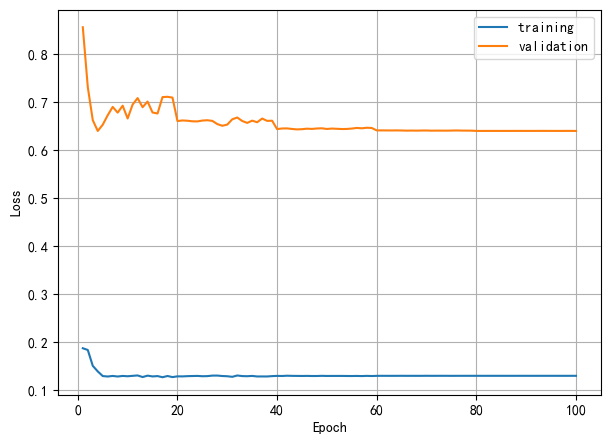

In [49]:
# from function import plotloss
def plot_lc(plot_train, plot_val):

    # epochs
    n_epochs = len(plot_train)

    # X axis
    x = [i for i in range(1, n_epochs+1)]

    # plot loss
    fig = plt.figure(figsize=(7,5))
    fig.patch.set_facecolor('white')

    plt.xlabel('epoch')
    plt.plot(x, plot_train[:], label='training ')
    plt.plot(x, plot_val[:], label='validation')
    
#     plt.axvline(24,linestyle = '--',color = 'dimgrey')
    
    plt.legend()
#     plt.legend(loc='lower left', bbox_to_anchor= (0.0, 1.01), ncol=2, 
#             borderaxespad=0, frameon=False)
#     plt.tight_layout()
#     plt.title('Learning curve')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
#     plt.xlim((0,300))
    plt.grid(True)
#     plt.savefig('learning curve with stopping line.png')
    plt.show
    
plot_lc(history["train"], history["valid"])

In [50]:
prediction = []
true_labels = y_test
for i in range(x_test.shape[0]):
    data = x_test[i,:,:,:].reshape(1,1,200,-1)
#   X_test.append(data)
    data = torch.from_numpy(data).float().to(device)
    output = model(data)
    output = output.squeeze()>0.5
    prediction.append(output.cpu().detach().numpy())

In [51]:
np.array(prediction)*1

array([1, 1, 0, 0, 0, 0, 0, 0, 0])

In [52]:
y_test

array([1, 1, 1, 0, 1, 0, 0, 0, 0], dtype=int64)

In [53]:
print("prediction: ",np.array(prediction)*1)
print("true label: ",y_test)
print("accuracy: ",np.sum(np.array(prediction)*1==y_test)/len(y_test))

prediction:  [1 1 0 0 0 0 0 0 0]
true label:  [1 1 1 0 1 0 0 0 0]
accuracy:  0.7777777777777778


In [54]:
prediction = []
true_labels = y_valid
for i in range(x_valid.shape[0]):
    data = x_valid[i,:,:,:].reshape(1,1,200,-1)
#   X_test.append(data)
    data = torch.from_numpy(data).float().to(device)
    output = model(data)
    output = output.squeeze()>0.5
    prediction.append(output.cpu().detach().numpy())
prediction

[array(False),
 array(True),
 array(False),
 array(False),
 array(True),
 array(False),
 array(True),
 array(False),
 array(False)]

In [55]:
print("prediction: ",np.array(prediction)*1)
print("true label: ",y_valid)
print("accuracy: ",np.sum(np.array(prediction)*1==y_test)/len(y_valid))

prediction:  [0 1 0 0 1 0 1 0 0]
true label:  [0 0 1 0 0 0 1 0 0]
accuracy:  0.6666666666666666


#### 导入已有模型进行评估

In [14]:
model_path = r"D:\XHQ_study_data\ING\脑脊液病人拉曼光谱分类\code\important\241224_100_2trained_model_currentbestmodel.pt"
model = Net()
model.to(device)
model.load_state_dict(torch.load(model_path))
prediction = []
true_labels = y_test
for i in range(x_test.shape[0]):
    data = x_test[i,:,:,:].reshape(1,1,200,-1)
    data = torch.from_numpy(data).float().to(device)
    print(data.shape)
    output = model(data)
    output = output.squeeze()>0.5
    prediction.append(output.cpu().detach().numpy())
print("prediction: ",np.array(prediction)*1)
print("true label: ",y_test)
print("accuracy: ",np.sum(np.array(prediction)*1==y_test)/len(y_test))

NameError: name 'Net' is not defined

In [24]:
# 预测未知样本的类别
prediction = []
for i in range(x_unknown.shape[0]):
    data = x_unknown[i,:,:,:].reshape(1,1,200,-1)
    print(x_unknown[i,:,:,:].shape)
    data = torch.from_numpy(data).float().to(device)
    output = model(data)
    output = output.squeeze()>0.5
    prediction.append(output.cpu().detach().numpy())
print("prediction: ",np.array(prediction)*1)

(1, 200, 200)
(1, 200, 200)
(1, 200, 200)
(1, 200, 200)
(1, 200, 200)
(1, 200, 200)
prediction:  [1 0 0 0 0 0]
